# Task 2 — PPO (ATML PA2)
Runtime → Change runtime type → **GPU**. Run cells top to bottom.

**Disconnect-safe:** `outputs/` and `results/` are symlinked to Google Drive (`MyDrive/ATML_PA2_task2`); finished runs/evals are detected and skipped on re-run.

Pipeline: validate → standard 20-update continuation → held-out evals (reference / midpoint / standard) → cached-rollout clipping study → ε forks → β_KL forks → tables/plots → qualitative candidates.

**All hyper-parameters come from the release `configs/ppo.yaml` / `base.yaml` (no overrides, no code-side defaults).**

In [ ]:
%env PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
!nvidia-smi | head -15
import os
if not os.path.isdir('/content/ATML-PA2-LLM-PostTraining'):
    !git clone https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git
%cd /content/ATML-PA2-LLM-PostTraining

env: PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
Mon Oct 12 19:13:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
D='/content/drive/MyDrive/ATML_PA2_task2'
for n in ('outputs','results'):
    os.makedirs(f'{D}/{n}',exist_ok=True)
    if os.path.isdir(n) and not os.path.islink(n): os.system(f'rm -rf {n}')
    if not os.path.islink(n): os.symlink(f'{D}/{n}',n)
!ls -la outputs results

Mounted at /content/drive
lrwxrwxrwx 1 root root 45 Oct 12 19:13 outputs -> /content/drive/MyDrive/ATML_PA2_task2/outputs
lrwxrwxrwx 1 root root 45 Oct 12 19:13 results -> /content/drive/MyDrive/ATML_PA2_task2/results


In [ ]:
!pip install -q -r requirements.txt
!python -m scripts.download_assets
!python -m scripts.validate_assets

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 96.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.9/530.9 kB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 32.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Source: AbDu11aHHH/ATML-PA2-assets
Revis

## Student code
- **PPO objective fix** in `ppo.py`: the starter used `torch.maximum`; the clipped surrogate is `torch.minimum` (pessimistic bound). GAE / KL shaping / whitening verified by unit tests.
- Real multi-epoch PPO (`ppo_epochs` from the config); ratio recomputed every epoch.
- Trainable LoRA/head weights kept in fp32 (+autocast fp16, GradScaler) — fp16 AdamW states underflow to NaN.
- No silent NaN guards: any non-finite loss/value/advantage raises immediately.
- Prompts longer than `max_prompt_length` are skipped deterministically; skipped counts are logged.
- Dropout (incl. LoRA dropout) off during PPO so π_θ = π_old at epoch 1.

In [ ]:
%%writefile task2_ppo/ppo.py
from __future__ import annotations

import torch

from common.metrics import masked_mean


def compute_gae(rewards, values, mask, gamma, lam):
    """Token-level GAE over response positions.

    rewards, values, mask: [batch, response_steps]. Padding positions must have mask=0.
    The final valid response position bootstraps with zero.
    delta_t = r_t + gamma * V(s_{t+1}) - V(s_t);  A_t = sum_k (gamma*lam)^k delta_{t+k}
    """
    batch, steps = rewards.shape
    advantages = torch.zeros_like(rewards)
    last_adv = torch.zeros(batch, device=rewards.device, dtype=rewards.dtype)

    for t in reversed(range(steps)):
        current_valid = mask[:, t]
        if t + 1 < steps:
            next_valid = mask[:, t + 1]
            next_value = values[:, t + 1] * next_valid
        else:
            next_valid = torch.zeros_like(current_valid)
            next_value = torch.zeros_like(last_adv)

        delta = rewards[:, t] + gamma * next_value - values[:, t]
        last_adv = delta + gamma * lam * next_valid * last_adv
        last_adv = last_adv * current_valid
        advantages[:, t] = last_adv

    returns = advantages + values
    return advantages, returns


def shaped_rewards(task_reward, policy_logp, ref_logp, response_mask, beta_kl):
    """r_t = r_task * 1[t = T] - beta_KL * (log pi_theta - log pi_ref) on sampled tokens."""
    rewards = -float(beta_kl) * (policy_logp - ref_logp) * response_mask
    for b in range(rewards.shape[0]):
        valid = int(response_mask[b].sum().item())
        if valid > 0:
            rewards[b, valid - 1] += task_reward[b]
    return rewards


def ppo_policy_loss(new_logp, old_logp, advantage, mask, eps):
    """PPO clipped surrogate: -E[min(rho*A, clip(rho, 1-eps, 1+eps)*A)] plus diagnostics."""
    ratio = torch.exp(new_logp - old_logp)
    surr1 = ratio * advantage
    surr2 = ratio.clamp(1.0 - eps, 1.0 + eps) * advantage
    objective = torch.minimum(surr1, surr2)

    loss = -masked_mean(objective, mask)
    affected = ((ratio < (1.0 - eps)) | (ratio > (1.0 + eps))).float()
    clip_fraction = masked_mean(affected, mask)
    return loss, ratio.detach(), clip_fraction.detach()


def value_mse_loss(predicted_values, returns, mask):
    """Masked mean squared error. Non-finite inputs are an error, not something to hide."""
    if not (torch.isfinite(predicted_values).all() and torch.isfinite(returns).all()):
        raise FloatingPointError("non-finite value predictions or returns reached the value loss")
    return masked_mean((predicted_values - returns) ** 2, mask)


def normalize_advantages(advantages, mask, eps=1e-6):
    """Whiten advantages over the valid (masked) tokens of the batch."""
    m = mask.bool()
    if not torch.isfinite(advantages[m]).all():
        raise FloatingPointError("non-finite advantages (check the critic / rewards)")
    valid = advantages[m]
    if valid.numel() <= 1:
        return advantages * mask
    mean = valid.mean()
    std = valid.std(unbiased=False).clamp_min(eps)
    return ((advantages - mean) / std) * mask


Overwriting task2_ppo/ppo.py


In [ ]:
%%writefile task2_ppo/utils.py
from __future__ import annotations

import torch

from common.data import prompt_messages
from common.generation import batch_generate
from common.models import token_values


def filter_prompts(tokenizer, rows, max_prompt_length):
    """Deterministically skip prompts longer than max_prompt_length (no truncation)."""
    kept, skipped = [], []
    for i, row in enumerate(rows):
        ids = tokenizer.apply_chat_template(prompt_messages(row), tokenize=True, add_generation_prompt=True)
        if not isinstance(ids, list):
            ids = ids["input_ids"]
        (kept if len(ids) <= max_prompt_length else skipped).append(i)
    return kept, skipped


def set_ppo_mode(model):
    """Train mode with every Dropout (incl. LoRA dropout) off, so pi_theta == pi_old at epoch 1."""
    model.train()
    for m in model.modules():
        if isinstance(m, torch.nn.Dropout):
            m.eval()


def trainable_to_fp32(model):
    """Master weights for trainable params in fp32 (fp16 AdamW states underflow -> NaN)."""
    for p in model.parameters():
        if p.requires_grad and p.dtype != torch.float32:
            p.data = p.data.float()
    return model


def _autocast(device):
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda")


def generate_rollout(model, tok, prompts, cfg, max_new):
    g = cfg["generation"]
    prev = model.config.use_cache
    model.eval()
    model.config.use_cache = True
    try:
        gen = batch_generate(model, tok, prompts, int(cfg["max_prompt_length"]), max_new,
                             g["temperature"], g["top_p"], g["do_sample"])
        return {k: (v.detach().clone() if torch.is_tensor(v) else v) for k, v in gen.items()}
    finally:
        model.config.use_cache = prev


def response_logprobs(model, sequences, attention_mask, prompt_width, response_ids,
                      grad=False, entropy=False, chunk_size=1):
    """Log-prob of each response token under `model` (and optionally the token entropy).

    sequences = [prompt (width prompt_width) | response (width W)].  Returns [B, W] tensors.
    """
    W = response_ids.shape[1]
    assert sequences.shape[1] == prompt_width + W, "sequences must be prompt_width + response width"
    lps, ents = [], []
    for s in range(0, sequences.shape[0], chunk_size):
        e = min(s + chunk_size, sequences.shape[0])
        with torch.set_grad_enabled(grad), _autocast(sequences.device):
            out = model(input_ids=sequences[s:e], attention_mask=attention_mask[s:e],
                        use_cache=False, return_dict=True, logits_to_keep=W + 1)
        logits = out.logits[:, :-1, :].float()  # positions that predict the W response tokens
        del out
        logp = torch.log_softmax(logits, dim=-1)
        del logits
        lps.append(logp.gather(-1, response_ids[s:e].unsqueeze(-1)).squeeze(-1))
        if entropy:
            with torch.no_grad():
                ents.append(-(logp.exp() * logp).sum(-1))
        del logp
    return torch.cat(lps, 0), (torch.cat(ents, 0) if entropy else None)


def response_values(value_model, sequences, attention_mask, prompt_width, n_resp):
    with _autocast(sequences.device):
        v = token_values(value_model, sequences, attention_mask)
    v = v.float()
    return v[:, prompt_width - 1: prompt_width - 1 + n_resp]


def optimizer_step(scaler, opt, params, max_grad_norm):
    """Unscale, clip, step (the scaler skips the step on inf/nan grads). Returns (grad_norm, stepped)."""
    scaler.unscale_(opt)
    gn = torch.nn.utils.clip_grad_norm_(params, max_grad_norm)
    before = scaler.get_scale()
    scaler.step(opt)
    scaler.update()
    opt.zero_grad(set_to_none=True)
    stepped = scaler.get_scale() >= before  # scale shrinks only when a step was skipped
    return float(gn), bool(stepped)


Writing task2_ppo/utils.py


In [ ]:
%%writefile task2_ppo/continue_train.py
from __future__ import annotations

import argparse
import json
import time

import torch
from torch.optim import AdamW

from common.data import load_yaml, prompt_messages, read_jsonl, repo_path
from common.generation import score_reward_pairs
from common.logging_utils import append_jsonl, set_seed
from common.metrics import masked_mean
from common.models import (
    clear_gpu,
    load_policy,
    load_reward_model,
    load_tokenizer,
    load_value_model,
    reference_mode,
    trainable_parameters,
    value_parameter_groups,
)
from task2_ppo.ppo import compute_gae, normalize_advantages, ppo_policy_loss, shaped_rewards, value_mse_loss
from task2_ppo.utils import (
    filter_prompts,
    generate_rollout,
    optimizer_step,
    response_logprobs,
    response_values,
    set_ppo_mode,
    trainable_to_fp32,
)


def fork_name(eps: float, kl: float) -> str:
    return f"eps{eps:g}_kl{kl:g}"


def _check_finite(name, t):
    if not torch.isfinite(t).all():
        raise FloatingPointError(f"non-finite values in {name}")


def run_ppo(config_path: str, output_dir: str, updates: int, clip_epsilon: float, kl_beta: float, run_name: str):
    cfg = load_yaml(config_path)
    set_seed(int(cfg["seed"]))
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    out_dir = repo_path(output_dir).joinpath(run_name)
    out_dir.mkdir(parents=True, exist_ok=True)

    # ---- models: policy + critic start from the supplied PPO midpoint -------------------
    tok = load_tokenizer(cfg["base_model"])
    policy = trainable_to_fp32(load_policy(cfg, adapter_path=cfg["paths"]["ppo_midpoint_policy"], trainable=True))
    val_model = trainable_to_fp32(
        load_value_model(cfg, cfg["paths"]["ppo_midpoint_value"], train_mode=cfg["value_train_mode"]))
    ref_model = load_policy(cfg, adapter_path=None, trainable=False)
    rm, rtok = load_reward_model(cfg)

    prompt_pool = read_jsonl(cfg["paths"]["rl_prompt_train"])
    kept_indices, skipped_indices = filter_prompts(tok, prompt_pool, int(cfg["max_prompt_length"]))
    print(f"Kept prompts: {len(kept_indices)}, Skipped prompts: {len(skipped_indices)}")

    # ---- optimisers / hyper-parameters, all from the release config ----------------------
    policy_params = trainable_parameters(policy)
    policy_opt = AdamW(policy_params, lr=float(cfg["policy_learning_rate"]))
    val_groups = value_parameter_groups(val_model, lora_lr=float(cfg["value_lora_learning_rate"]),
                                        head_lr=float(cfg["value_head_learning_rate"]))
    val_opt = AdamW(val_groups)
    value_params = [p for g in val_groups for p in g["params"]]
    policy_scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")
    value_scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")

    prompts_per_update = int(cfg["prompts_per_update"])
    ppo_epochs = int(cfg["ppo_epochs"])
    max_new_tokens = int(cfg["max_response_length"])
    gamma, gae_lambda = float(cfg["gamma"]), float(cfg["gae_lambda"])
    max_grad_norm = float(cfg["max_grad_norm"])
    missing_eos_penalty = float(cfg["missing_eos_penalty"])

    log_path = repo_path(cfg["results_dir"]).joinpath(f"train_log_{run_name}.jsonl")
    log_path.parent.mkdir(parents=True, exist_ok=True)
    if log_path.exists():
        log_path.unlink()

    if dev.type == "cuda":
        torch.cuda.reset_peak_memory_stats(dev)
    start_time = time.time()
    prompt_idx = 0

    for u in range(1, updates + 1):
        t0 = time.time()

        # 1. prompts for this update (deterministic order, identical across forks) ----------
        batch_msgs = []
        for _ in range(prompts_per_update):
            idx = kept_indices[prompt_idx % len(kept_indices)]
            prompt_idx += 1
            batch_msgs.append(prompt_messages(prompt_pool[idx]))

        # 2. on-policy rollout from the current policy (= pi_old) ---------------------------
        set_ppo_mode(policy)
        with torch.no_grad():
            rollout = generate_rollout(policy, tok, batch_msgs, cfg, max_new_tokens)
        seqs = rollout["sequences"].to(dev)
        attn_mask = rollout["attention_mask"].to(dev)
        response_mask = rollout["response_mask"].to(dev).float()
        pw = rollout["prompt_width"]
        resp_ids = rollout["response_ids"].to(dev)
        responses = rollout["responses"]
        lengths = torch.as_tensor(rollout["response_lengths"], dtype=torch.float32)
        eos_flags = [bool(x) for x in rollout["terminated_with_eos"]]
        W = resp_ids.shape[1]

        # 3. learned reward (+ penalty for not terminating) ---------------------------------
        with torch.no_grad():
            raw_rewards = score_reward_pairs(rm, rtok, batch_msgs, responses,
                                             max_length=int(cfg["reward_max_length"])).to(dev).float()
            penalties = torch.tensor([0.0 if f else missing_eos_penalty for f in eos_flags],
                                     device=dev, dtype=raw_rewards.dtype)
            task_rewards = raw_rewards - penalties

        # 4. old / reference log-probs, entropy, critic values, GAE ---------------------------
        set_ppo_mode(val_model)
        with torch.no_grad():
            old_logprobs, token_entropy = response_logprobs(policy, seqs, attn_mask, pw, resp_ids, entropy=True)
            with reference_mode(ref_model):
                ref_logprobs, _ = response_logprobs(ref_model, seqs, attn_mask, pw, resp_ids)
            entropy = float(masked_mean(token_entropy, response_mask))
            del token_entropy

            values = response_values(val_model, seqs, attn_mask, pw, W)
            _check_finite("critic values", values)
            rewards = shaped_rewards(task_rewards, old_logprobs, ref_logprobs, response_mask, kl_beta)
            advantages, returns = compute_gae(rewards, values, response_mask, gamma, gae_lambda)
            norm_adv = normalize_advantages(advantages, response_mask)

        kl_token = float(masked_mean(old_logprobs - ref_logprobs, response_mask))  # sampled-token KL
        n_tokens = response_mask.sum(-1)
        total_tokens = n_tokens.sum()

        # 5. PPO epochs on this rollout (ratio is recomputed every epoch) --------------------
        ep_pl, ep_vl, ep_gp, ep_gv, ep_clip, ep_rmax, ep_rmean, skipped_steps = [], [], [], [], [], [], [], 0
        for _ in range(ppo_epochs):
            set_ppo_mode(policy)
            set_ppo_mode(val_model)

            # policy: token-weighted mean over the whole batch, one sequence at a time
            pl_total, clip_num, ratios = 0.0, 0.0, []
            for i in range(seqs.shape[0]):
                sl = slice(i, i + 1)
                new_lp, _ = response_logprobs(policy, seqs[sl], attn_mask[sl], pw, resp_ids[sl], grad=True)
                loss_i, ratio_i, clip_i = ppo_policy_loss(new_lp, old_logprobs[sl], norm_adv[sl],
                                                          response_mask[sl], clip_epsilon)
                if not torch.isfinite(loss_i):
                    raise FloatingPointError(f"non-finite policy loss at update {u}")
                w = n_tokens[i] / total_tokens
                policy_scaler.scale(loss_i * w).backward()
                pl_total += float(loss_i.detach() * w)
                clip_num += float(clip_i * n_tokens[i])
                ratios.append(ratio_i[response_mask[sl].bool()])
            g_p, stepped = optimizer_step(policy_scaler, policy_opt, policy_params, max_grad_norm)
            skipped_steps += int(not stepped)
            ratios = torch.cat(ratios)

            # critic
            vl_total = 0.0
            for i in range(seqs.shape[0]):
                sl = slice(i, i + 1)
                pred = response_values(val_model, seqs[sl], attn_mask[sl], pw, W)
                loss_v = value_mse_loss(pred, returns[sl], response_mask[sl])
                value_scaler.scale(loss_v * (n_tokens[i] / total_tokens)).backward()
                vl_total += float(loss_v.detach() * n_tokens[i] / total_tokens)
            g_v, stepped = optimizer_step(value_scaler, val_opt, value_params, max_grad_norm)
            skipped_steps += int(not stepped)

            ep_pl.append(pl_total); ep_vl.append(vl_total); ep_gp.append(g_p); ep_gv.append(g_v)
            ep_clip.append(clip_num / float(total_tokens))
            ep_rmax.append(float(ratios.max())); ep_rmean.append(float(ratios.mean()))

        # 6. diagnostics -----------------------------------------------------------------------
        mval, mret = values[response_mask.bool()], returns[response_mask.bool()]
        ret_var = mret.var(unbiased=False)
        explained_var = float(1.0 - ((mret - mval) ** 2).mean() / ret_var) if ret_var > 0 else float("nan")
        mean = lambda xs: sum(xs) / len(xs)  # noqa: E731
        peak_vram = torch.cuda.max_memory_allocated(dev) / 1024 ** 3 if dev.type == "cuda" else 0.0

        row = {
            "update": u,
            "reward_raw": float(raw_rewards.mean()),
            "reward_task": float(task_rewards.mean()),
            "kl_token": kl_token,
            "policy_loss": mean(ep_pl),
            "value_loss": mean(ep_vl),
            "entropy": entropy,
            "clip_fraction": mean(ep_clip),
            "clip_fraction_last_epoch": ep_clip[-1],
            "affected_fraction": mean(ep_clip),
            "ratio_max": max(ep_rmax),
            "ratio_mean": mean(ep_rmean),
            "grad_norm_policy": mean(ep_gp),
            "grad_norm_value": mean(ep_gv),
            "resp_len": float(lengths.mean()),
            "eos_rate": sum(eos_flags) / len(eos_flags),
            "value_mean": float(mval.mean()),
            "return_mean": float(mret.mean()),
            "explained_var": explained_var,
            "skipped_optimizer_steps": skipped_steps,
            "peak_vram_gb": peak_vram,
            "wall_clock_s": time.time() - t0,
        }
        append_jsonl(log_path, row)
        print(f"Update {u:02d} | R {row['reward_raw']:.3f} | KL {row['kl_token']:.4f} | "
              f"P {row['policy_loss']:.4f} | V {row['value_loss']:.3f} | clip {row['clip_fraction']:.3f} | "
              f"gP {row['grad_norm_policy']:.3f} | len {row['resp_len']:.0f} | skipped {skipped_steps}")

    # ---- save adapters + run metadata --------------------------------------------------------
    policy.save_pretrained(out_dir)
    val_model.save_pretrained(out_dir.joinpath("value_model"))
    meta = {"run_name": run_name, "updates": updates, "clip_epsilon": clip_epsilon, "kl_beta": kl_beta,
            "ppo_epochs": ppo_epochs, "prompts_per_update": prompts_per_update,
            "max_response_length": max_new_tokens,
            "wall_clock_s": time.time() - start_time,
            "peak_vram_gb": torch.cuda.max_memory_allocated(dev) / 1024 ** 3 if dev.type == "cuda" else 0.0,
            "gpu": torch.cuda.get_device_name(dev) if dev.type == "cuda" else "cpu"}
    text = json.dumps(meta, indent=2)
    repo_path(cfg["results_dir"]).joinpath(f"run_meta_{run_name}.json").write_text(text)
    out_dir.joinpath("run_meta.json").write_text(text)
    clear_gpu(policy, ref_model, val_model, rm)


def ensure_fork(config_path: str, eps: float, kl: float) -> tuple[str, str]:
    cfg = load_yaml(config_path)
    name = fork_name(eps, kl)
    output = f"outputs/task2_ppo/{name}"
    if repo_path(output).joinpath("adapter_config.json").exists():
        print(f"Fork {name} exists — skipping")
    else:
        run_ppo(config_path, "outputs/task2_ppo", int(cfg["fork_updates"]), eps, kl, name)
    return name, output


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/ppo.yaml")
    ap.add_argument("--output", default="outputs/task2_ppo")
    ap.add_argument("--updates", type=int)
    ap.add_argument("--clip-epsilon", type=float)
    ap.add_argument("--kl-beta", type=float)
    ap.add_argument("--run-name", default="standard")
    args = ap.parse_args()

    cfg = load_yaml(args.config)
    up = args.updates if args.updates is not None else int(cfg["updates"])
    eps = args.clip_epsilon if args.clip_epsilon is not None else float(cfg["clip_epsilon"])
    kl = args.kl_beta if args.kl_beta is not None else float(cfg["kl_beta"])
    run_ppo(args.config, args.output, up, eps, kl, args.run_name)


if __name__ == "__main__":
    main()


Overwriting task2_ppo/continue_train.py


In [ ]:
%%writefile task2_ppo/evaluate.py
from __future__ import annotations

import argparse
import json

import numpy as np
import torch

from common.data import load_yaml, prompt_messages, read_jsonl, repo_path
from common.generation import score_reward_pairs
from common.logging_utils import set_seed
from common.models import clear_gpu, load_policy, load_reward_model, load_tokenizer, reference_mode
from task2_ppo.utils import filter_prompts, generate_rollout, response_logprobs


def load_evaluation_bundle(config_path: str, adapter: str | None):
    cfg = load_yaml(config_path)
    return {
        "cfg": cfg,
        "rows": read_jsonl(cfg["paths"]["rl_prompt_eval"]),
        "tokenizer": load_tokenizer(cfg["base_model"]),
        "policy": load_policy(cfg, adapter_path=adapter, trainable=False),
        "reward": load_reward_model(cfg),
    }


@torch.no_grad()
def evaluate_policy(config_path: str, adapter: str | None, name: str, n_prompts: int | None = None):
    b = load_evaluation_bundle(config_path, adapter)
    cfg, tok, policy = b["cfg"], b["tokenizer"], b["policy"]
    rm, rtok = b["reward"]
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    kept, skipped = filter_prompts(tok, b["rows"], int(cfg["max_prompt_length"]))
    # Fixed held-out prompts: the first n kept prompts of the released eval pool (all of them if unspecified).
    n = n_prompts if n_prompts is not None else cfg.get("eval_prompts")
    sel = kept if n is None else kept[: int(n)]
    prompts = [prompt_messages(b["rows"][i]) for i in sel]
    max_new, bs = int(cfg["eval_max_response_length"]), int(cfg["eval_gen_batch"])
    set_seed(int(cfg["seed"]))

    recs = []
    for s in range(0, len(prompts), bs):
        chunk = prompts[s:s + bs]
        gen = generate_rollout(policy, tok, chunk, cfg, max_new)
        seq, attn = gen["sequences"].to(dev), gen["attention_mask"].to(dev)
        resp, mask = gen["response_ids"].to(dev), gen["response_mask"].to(dev).float()
        pw = gen["prompt_width"]
        rew = score_reward_pairs(rm, rtok, chunk, gen["responses"],
                                 max_length=int(cfg["reward_max_length"])).cpu().tolist()
        step = 2
        for k in range(0, len(chunk), step):
            sl = slice(k, k + step)
            plp, ent = response_logprobs(policy, seq[sl], attn[sl], pw, resp[sl], entropy=True)
            with reference_mode(policy):
                rlp, _ = response_logprobs(policy, seq[sl], attn[sl], pw, resp[sl])
            m = mask[sl]
            d = (plp - rlp) * m
            cnt = m.sum(-1)
            ent_mean = ((ent * m).sum(-1) / cnt).cpu().tolist()
            for j in range(plp.shape[0]):
                i = k + j
                recs.append({"source_index": sel[s + i], "prompt": chunk[i], "response": gen["responses"][i],
                             "reward": rew[i], "length": int(gen["response_lengths"][i]),
                             "kl_token_mean": float(d[j].sum() / cnt[j]), "kl_seq": float(d[j].sum()),
                             "entropy": ent_mean[j], "terminated": bool(gen["terminated_with_eos"][i]),
                             "truncated": bool(gen["truncated"][i])})
            del plp, rlp, ent

    L = np.array([r["length"] for r in recs], dtype=float)
    q1, q3 = np.percentile(L, [25, 75])
    res = {"name": name, "adapter": adapter, "seed": cfg["seed"], "n_prompts": len(recs), "source_indices": sel,
           "n_prompts_skipped_too_long": len(skipped),
           "reward_mean": float(np.mean([r["reward"] for r in recs])),
           "reward_std": float(np.std([r["reward"] for r in recs])),
           "kl_token_mean": float(np.mean([r["kl_token_mean"] for r in recs])),
           "kl_seq": float(np.mean([r["kl_seq"] for r in recs])),
           "entropy_mean": float(np.mean([r["entropy"] for r in recs])),
           "len_mean": float(L.mean()), "len_std": float(L.std()), "len_iqr": float(q3 - q1),
           "eos_rate": float(np.mean([r["terminated"] for r in recs])),
           "truncated_frac": float(np.mean([r["truncated"] for r in recs])),
           "max_new_tokens": max_new, "temperature": cfg["generation"]["temperature"],
           "top_p": cfg["generation"]["top_p"]}
    out_dir = repo_path(cfg["results_dir"]); out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / f"eval_{name}.json").write_text(json.dumps(res, indent=1))
    with open(out_dir / f"generations_{name}.jsonl", "w") as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(json.dumps(res, indent=1))
    clear_gpu(b)
    return res


def ensure_eval(config_path: str, adapter: str | None, name: str):
    cfg = load_yaml(config_path)
    path = repo_path(cfg["results_dir"]).joinpath(f"eval_{name}.json")
    if path.exists():
        print(f"[eval {name}] exists — skipping")
        return json.loads(path.read_text())
    return evaluate_policy(config_path, adapter, name)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/ppo.yaml")
    ap.add_argument("--adapter", help="omit (or 'none') to evaluate the frozen reference model")
    ap.add_argument("--name", default="standard")
    ap.add_argument("--n-prompts", type=int)
    args = ap.parse_args()
    ad = None if args.adapter in (None, "none") else args.adapter
    evaluate_policy(args.config, ad, args.name, args.n_prompts)


if __name__ == "__main__":
    main()


Overwriting task2_ppo/evaluate.py


In [ ]:
%%writefile task2_ppo/ablate_kl.py
from __future__ import annotations

import argparse
import json

from common.data import load_yaml, repo_path
from task2_ppo.continue_train import ensure_fork
from task2_ppo.evaluate import ensure_eval


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/ppo.yaml")
    args = ap.parse_args()
    cfg = load_yaml(args.config)
    eps = float(cfg["clip_epsilon"])
    print("KL beta conditions:", cfg["kl_values"], "| fork updates:", cfg["fork_updates"], "| eps fixed at", eps)
    rows = []
    for kl in cfg["kl_values"]:
        name, out = ensure_fork(args.config, eps, float(kl))
        rows.append(ensure_eval(args.config, out, name))
    (repo_path(cfg["results_dir"]) / "kl_ablation_summary.json").write_text(json.dumps(rows, indent=1))


if __name__ == "__main__":
    main()


Overwriting task2_ppo/ablate_kl.py


In [ ]:
%%writefile task2_ppo/analyze_clipping.py
from __future__ import annotations

import argparse
import json

import torch
from torch.optim import AdamW
from torch.nn.utils.rnn import pad_sequence

from common.data import load_yaml, read_jsonl, repo_path
from common.logging_utils import set_seed
from common.models import clear_gpu, load_policy, load_tokenizer, reference_mode, trainable_parameters
from task2_ppo.continue_train import ensure_fork
from task2_ppo.evaluate import ensure_eval
from task2_ppo.ppo import compute_gae, normalize_advantages, ppo_policy_loss, shaped_rewards
from task2_ppo.utils import optimizer_step, response_logprobs, set_ppo_mode, trainable_to_fp32


def load_cached_rollouts(path):
    rows = torch.load(repo_path(path), map_location="cpu", weights_only=False)
    if not isinstance(rows, list) or not rows:
        raise ValueError("Expected a non-empty list in the supplied PPO rollout cache")
    return rows


def build_items(cfg, tok, rows):
    """Use exactly what the cache stores: old/ref log-probs, critic values, effective terminal reward."""
    prompt_rows = read_jsonl(cfg["paths"]["rl_prompt_train"])
    from common.data import prompt_messages
    eos = tok.eos_token_id
    items = []
    for r in rows:
        pm = prompt_messages(prompt_rows[int(r["source_index"])])
        p_ids = tok.apply_chat_template(pm, tokenize=True, add_generation_prompt=True)
        if not isinstance(p_ids, list):
            p_ids = p_ids["input_ids"]
        old = torch.as_tensor(r["old_logprobs"]).float().flatten()
        ref = torch.as_tensor(r["ref_logprobs"]).float().flatten()
        val = torch.as_tensor(r["values"]).float().flatten()
        n = len(old)
        assert len(ref) == n and len(val) == n, "cached old/ref/value lengths disagree"
        r_ids = tok(r["response"], add_special_tokens=False)["input_ids"]
        if bool(r["terminated_with_eos"]) and len(r_ids) + 1 == n:
            r_ids = r_ids + [eos]  # the decoded text drops the EOS token the cache scored
        if len(r_ids) != n:
            raise ValueError(f"source_index {r['source_index']}: re-tokenised response has {len(r_ids)} tokens "
                             f"but the cache has {n} log-probs; cannot align tokens to cached log-probs")
        items.append({"source_index": int(r["source_index"]), "p_ids": p_ids, "r_ids": r_ids, "n": n,
                      "old": old, "ref": ref, "values": val,
                      "reward": float(r["effective_terminal_reward"])})
    return items


def row_logp(policy, item, dev, grad=False):
    ids = torch.tensor([item["p_ids"] + item["r_ids"]], device=dev)
    pw = len(item["p_ids"])
    lp, _ = response_logprobs(policy, ids, torch.ones_like(ids), pw, ids[:, pw:], grad=grad)
    return lp[0]


def surrogate_metrics(ratios, advs, eps):
    r, a = torch.cat(ratios), torch.cat(advs)
    unc, clp = r * a, r.clamp(1 - eps, 1 + eps) * a
    return {"eps": eps, "surrogate_clipped": float(torch.minimum(unc, clp).mean()),
            "surrogate_unclipped": float(unc.mean()),
            "clip_fraction": float(((r < 1 - eps) | (r > 1 + eps)).float().mean()),
            "affected_fraction": float((clp < unc - 1e-12).float().mean()),
            "ratio_mean_abs_dev": float((r - 1).abs().mean()), "ratio_max": float(r.max()),
            "ratio_min": float(r.min()), "n_tokens": int(r.numel())}


def probe_updates(cfg, items, advs, eps, lr, steps, dev):
    """Take `steps` gradient steps on the fixed cached batch and track how the ratios spread."""
    policy = trainable_to_fp32(load_policy(cfg, adapter_path=cfg["paths"]["ppo_midpoint_policy"], trainable=True))
    params = trainable_parameters(policy)
    opt = AdamW(params, lr=lr)
    scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")
    total = sum(it["n"] for it in items)
    curve = []
    for step in range(steps + 1):
        set_ppo_mode(policy)
        ratios, adv_l = [], []
        for it, adv in zip(items, advs):
            train = step < steps
            with torch.set_grad_enabled(train):
                lp = row_logp(policy, it, dev, grad=train)
                loss, ratio, _ = ppo_policy_loss(lp[None], it["old"].to(dev)[None], adv.to(dev)[None],
                                                 torch.ones_like(lp)[None], eps)
                if train:
                    scaler.scale(loss * it["n"] / total).backward()
            ratios.append(ratio[0]); adv_l.append(adv.to(dev))
        curve.append({"step": step, **surrogate_metrics(ratios, adv_l, eps)})
        if step < steps:
            optimizer_step(scaler, opt, params, float(cfg["max_grad_norm"]))
    clear_gpu(policy, opt)
    return curve


def run_cached_study(config_path):
    cfg = load_yaml(config_path)
    set_seed(int(cfg["seed"]))
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    rows = load_cached_rollouts(cfg["cached_rollouts"])
    tok = load_tokenizer(cfg["base_model"])
    items = build_items(cfg, tok, rows)

    # current midpoint policy / reference vs the cached log-probs (consistency check + ratios)
    policy = load_policy(cfg, adapter_path=cfg["paths"]["ppo_midpoint_policy"], trainable=False)
    new_l, ref_chk = [], []
    with torch.no_grad():
        for it in items:
            new_l.append(row_logp(policy, it, dev).float())
            with reference_mode(policy):
                ref_chk.append(row_logp(policy, it, dev).float())
    old = [it["old"].to(dev) for it in items]
    ref = [it["ref"].to(dev) for it in items]
    check = {"mean_abs_diff_policy_vs_cached_old": float(torch.cat([(a - b).abs() for a, b in zip(new_l, old)]).mean()),
             "mean_abs_diff_reference_vs_cached_ref": float(torch.cat([(a - b).abs() for a, b in zip(ref_chk, ref)]).mean()),
             "n_rollouts": len(items), "n_tokens": sum(it["n"] for it in items),
             "reward_source": "cache.effective_terminal_reward",
             "reward_mean": sum(it["reward"] for it in items) / len(items),
             "source_indices": [it["source_index"] for it in items]}
    print(json.dumps(check, indent=1))
    clear_gpu(policy)

    # advantages from the cached critic values, rewards, and old/ref log-probs
    olds, refs = pad_sequence(old, batch_first=True), pad_sequence(ref, batch_first=True)
    values = pad_sequence([it["values"].to(dev) for it in items], batch_first=True)
    mask = pad_sequence([torch.ones(it["n"], device=dev) for it in items], batch_first=True)
    rew = torch.tensor([it["reward"] for it in items], device=dev)
    rewards = shaped_rewards(rew, olds, refs, mask, float(cfg["kl_beta"]))
    adv, _ = compute_gae(rewards, values, mask, float(cfg["gamma"]), float(cfg["gae_lambda"]))
    adv = normalize_advantages(adv, mask)
    advs = [adv[i, : it["n"]] for i, it in enumerate(items)]

    ratios = [torch.exp(a - b) for a, b in zip(new_l, old)]
    static = [surrogate_metrics(ratios, advs, float(e)) for e in cfg["clip_values"]]

    steps = int(cfg["clip_probe_steps"])
    lr0 = float(cfg["policy_learning_rate"])
    probes = []
    for mult in cfg["clip_probe_lr_mult"]:
        for e in cfg["clip_values"]:
            probes.append({"eps": float(e), "lr": lr0 * mult, "lr_mult": mult,
                           "curve": probe_updates(cfg, items, advs, float(e), lr0 * mult, steps, dev)})

    res = {"check": check, "static": static, "probes": probes, "kl_beta": cfg["kl_beta"],
           "gamma": cfg["gamma"], "gae_lambda": cfg["gae_lambda"]}
    out = repo_path(cfg["results_dir"]); out.mkdir(parents=True, exist_ok=True)
    (out / "cached_clipping_study.json").write_text(json.dumps(res, indent=1))
    print(json.dumps(static, indent=1))
    return res


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/ppo.yaml")
    ap.add_argument("--skip-cached", action="store_true")
    ap.add_argument("--skip-forks", action="store_true")
    args = ap.parse_args()
    cfg = load_yaml(args.config)
    if not args.skip_cached:
        run_cached_study(args.config)
        clear_gpu()
    if not args.skip_forks:
        kl = float(cfg["kl_beta"])
        for e in cfg["clip_values"]:
            name, out = ensure_fork(args.config, float(e), kl)
            ensure_eval(args.config, out, name)
            clear_gpu()


if __name__ == "__main__":
    main()


Overwriting task2_ppo/analyze_clipping.py


In [ ]:
import os
os.makedirs('tests', exist_ok=True)
open('tests/test_ppo.py', 'w').write('''import math, torch
from task2_ppo.ppo import compute_gae, ppo_policy_loss, shaped_rewards, normalize_advantages


def test_clip_is_pessimistic_min():
    eps = 0.2
    new = torch.tensor([[math.log(2.0)]], requires_grad=True)
    loss, ratio, cf = ppo_policy_loss(new, torch.zeros(1, 1), torch.tensor([[1.0]]), torch.ones(1, 1), eps)
    assert math.isclose(float(loss.detach()), -1.2, rel_tol=1e-5)
    loss.backward(); assert float(new.grad) == 0.0 and float(cf) == 1.0
    loss, _, _ = ppo_policy_loss(torch.tensor([[math.log(2.0)]]), torch.zeros(1, 1), torch.tensor([[-1.0]]), torch.ones(1, 1), eps)
    assert math.isclose(float(loss.detach()), 2.0, rel_tol=1e-5)


def test_on_policy_ratio_one():
    lp = torch.randn(2, 5)
    loss, ratio, cf = ppo_policy_loss(lp, lp.clone(), torch.randn(2, 5), torch.ones(2, 5), 0.2)
    assert torch.allclose(ratio, torch.ones(2, 5)) and float(cf) == 0.0


def test_gae_terminal_reward():
    r = torch.tensor([[0., 0., 1.]]); v = torch.zeros(1, 3); m = torch.ones(1, 3)
    adv, ret = compute_gae(r, v, m, gamma=1.0, lam=0.95)
    assert torch.allclose(adv, torch.tensor([[0.9025, 0.95, 1.0]]), atol=1e-4)
    adv, _ = compute_gae(r[:, :3], v, torch.tensor([[1., 1., 0.]]), gamma=1.0, lam=0.95)
    assert float(adv[0, 2]) == 0.0


def test_shaped_reward_places_terminal_and_kl():
    lp, ref = torch.tensor([[-1., -1., -1.]]), torch.tensor([[-2., -2., -2.]])
    rw = shaped_rewards(torch.tensor([2.0]), lp, ref, torch.tensor([[1., 1., 0.]]), 0.1)
    assert torch.allclose(rw, torch.tensor([[-0.1, 1.9, 0.0]]), atol=1e-6)


def test_normalize_raises_on_nan():
    import pytest
    with pytest.raises(FloatingPointError):
        normalize_advantages(torch.tensor([[float("nan"), 1.0]]), torch.ones(1, 2))
''')
!python -m pytest -q tests/test_ppo.py

.....                                                                    [100%]
5 passed in 2.89s


## Config
Release values are **not** modified. Only the evaluation/probe knobs that the release config does not define are appended (if missing).

In [ ]:
txt = open('configs/ppo.yaml').read()
add = ""
for k, line in [("eval_prompts", "eval_prompts: 64"), ("eval_gen_batch", "eval_gen_batch: 16"),
                ("clip_probe_steps", "clip_probe_steps: 5"), ("clip_probe_lr_mult", "clip_probe_lr_mult: [1, 20]")]:
    if k + ":" not in txt: add += line + "\n"
if add:
    open('configs/ppo.yaml', 'a').write("\n# --- added by student: evaluation / probe settings (release values untouched) ---\n" + add)
print(open('configs/ppo.yaml').read())

base_config: configs/base.yaml

# Short continuation from the supplied midpoint.
updates: 20
fork_updates: 8
prompts_per_update: 1
ppo_epochs: 2

policy_learning_rate: 3.0e-6
value_lora_learning_rate: 1.0e-4
value_head_learning_rate: 3.0e-4
value_train_mode: lora_head

clip_epsilon: 0.20
clip_values: [0.05, 0.20, 0.50]
kl_beta: 0.10
kl_values: [0.0, 0.10, 0.20]

gamma: 1.0
gae_lambda: 0.95
value_coef: 0.50
missing_eos_penalty: 1.0

max_prompt_length: 256
# Instructor midpoint training used this operational budget. The supplied midpoint has a
# documented long-tail termination limitation; use the larger cap for frozen evaluation.
max_response_length: 512
eval_max_response_length: 768
reward_max_length: 1280
max_grad_norm: 1.0

output: outputs/task2_ppo/standard
results_dir: results/task2_ppo
cached_rollouts: cached/ppo_rollout.pt

# --- added by student: evaluation / probe settings (release values untouched) ---
eval_prompts: 64
eval_gen_batch: 16
clip_probe_steps: 5
clip_probe_lr_mult:

## 0. Inspect the supplied bundle

In [ ]:
import torch, os
rows=torch.load('cached/ppo_rollout.pt',map_location='cpu',weights_only=False)
print(type(rows), len(rows)); r=rows[0]
for k,v in r.items(): print(f"{k:26s}", type(v).__name__, tuple(v.shape) if hasattr(v,'shape') else (len(v) if hasattr(v,'__len__') else v))
print(os.listdir('checkpoints/ppo_midpoint_policy'), os.listdir('checkpoints/ppo_midpoint_value'))

<class 'list'> 32
source_index               int 124
prompt_id                  str 64
response                   str 1378
response_tokens            int 313
terminated_with_eos        bool True
clipped_at_max             bool False
raw_terminal_reward        float 2.4375
effective_terminal_reward  float 2.4375
old_logprobs               Tensor (313,)
ref_logprobs               Tensor (313,)
values                     Tensor (313,)
['adapter_model.safetensors', 'added_tokens.json', 'special_tokens_map.json', 'tokenizer_config.json', 'merges.txt', 'chat_template.jinja', 'README.md', 'vocab.json', 'tokenizer.json', 'adapter_config.json'] ['added_tokens.json', 'special_tokens_map.json', 'tokenizer_config.json', 'merges.txt', 'chat_template.jinja', 'model.safetensors', 'vocab.json', 'tokenizer.json', 'config.json']


## 1a. Smoke test (1 update, release config) — catches errors before the long run

In [ ]:
!python -m task2_ppo.continue_train --run-name smoke --updates 1

I0000 00:00:1791832507.675752    3019 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791832510.256919    3019 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
tokenizer_config.json: 7.30kB [00:00, 24.4MB/s]
vocab.json: 2.78MB [00:00, 58.4MB/s]
merges.txt: 1.67MB [00:00, 126MB/s]
tokenizer.json: 7.03MB [00:00, 176MB/s]
config.json: 100% 660/660 [00:00<00:00, 5.55MB/s]
model.safetensors: 100% 3.09G/3.09G [00:21<00:00, 142MB/s]
generation_config.json: 100% 242/242 [00:00<00:00, 2.44MB/s]
config.json: 1.47kB [00:00, 622kB/s]
model.safetensors: 100% 3.09G/3.09G [00:29<00:00, 105MB/s]
Kept prompts: 944, Skipped prompts: 256
Update 01 | R 1.407 | KL 0.0001 | P -0.0001 | V 5.824 | clip 0.000 | gP 0.242 | len 512 | skipped 2


## 1b. Standard PPO continuation (20 updates from the supplied midpoint)
Logs reward, KL, policy/value loss, entropy, grad norms, clip fraction, length, peak VRAM, wall-clock.

In [ ]:
!python -m task2_ppo.continue_train --run-name standard

I0000 00:00:1791832668.568639    3857 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791832672.976223    3857 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Kept prompts: 944, Skipped prompts: 256
Update 01 | R 1.407 | KL 0.0001 | P -0.0001 | V 5.824 | clip 0.000 | gP 0.242 | len 512 | skipped 2
Update 02 | R 3.119 | KL -0.0004 | P 0.0000 | V 5.948 | clip 0.000 | gP 0.221 | len 467 | skipped 2
Update 03 | R 2.334 | KL 0.0001 | P -0.0001 | V 3.741 | clip 0.000 | gP 0.220 | len 300 | skipped 2
Update 04 | R 1.735 | KL 0.0004 | P 0.0000 | V 7.024 | clip 0.000 | gP nan | len 35 | skipped 3
Update 05 | R 0.199 | KL -0.0004 | P -0.0001 | V 8.585 | clip 0.000 | gP 0.243 | len 512 | skipped 1
Update 06 | R 3.387 | KL 0.0004 | P 

## 2. Held-out evaluation: frozen reference, supplied midpoint, standard continuation

In [ ]:
assert os.path.exists('outputs/task2_ppo/standard/adapter_config.json'), 'standard run missing — rerun the cell above'
from task2_ppo.evaluate import ensure_eval
ensure_eval('configs/ppo.yaml', None, 'reference')
ensure_eval('configs/ppo.yaml', 'checkpoints/ppo_midpoint_policy', 'midpoint')
ensure_eval('configs/ppo.yaml', 'outputs/task2_ppo/standard', 'standard')
print('done')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{
 "name": "reference",
 "adapter": null,
 "seed": 6304,
 "n_prompts": 64,
 "source_indices": [
  0,
  2,
  3,
  5,
  6,
  7,
  8,
  9,
  10,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  35,
  37,
  38,
  39,
  40,
  42,
  44,
  45,
  46,
  47,
  49,
  50,
  51,
  52,
  54,
  55,
  56,
  57,
  58,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  74,
  75
 ],
 "n_prompts_skipped_too_long": 35,
 "reward_mean": 1.764601707458496,
 "reward_std": 1.1504592707922339,
 "kl_token_mean": 0.0,
 "kl_seq": 0.0,
 "entropy_mean": 0.8809880414046347,
 "len_mean": 315.53125,
 "len_std": 274.48041646616156,
 "len_iqr": 525.5,
 "eos_rate": 0.859375,
 "truncated_frac": 0.140625,
 "max_new_tokens": 768,
 "temperature": 0.7,
 "top_p": 0.9
}
{
 "name": "midpoint",
 "adapter": "checkpoints/ppo_midpoint_policy",
 "seed": 6304,
 "n_prompts": 64,
 "source_indices": [
  0,
  2,
  3,
  5,
  6,
  7,
  

In [ ]:
# Timestamped backup of results + run metadata + code snapshot to Drive. Safe to re-run after any step.
import shutil, time, os, glob, subprocess
D='/content/drive/MyDrive/ATML_PA2_task2'
dst=f"{D}/backup_{time.strftime('%Y%m%d_%H%M%S')}"
os.makedirs(dst,exist_ok=True)
if os.path.isdir('results/task2_ppo'):
    shutil.copytree(os.path.realpath('results/task2_ppo'), f'{dst}/results_task2_ppo', dirs_exist_ok=True)
for f in glob.glob('outputs/task2_ppo/*/run_meta.json'):
    name=f.split('/')[-2]; os.makedirs(f'{dst}/run_meta',exist_ok=True); shutil.copy(f,f'{dst}/run_meta/{name}.json')
for d in ('task2_ppo','tests','common'):
    shutil.copytree(d, f'{dst}/code/{d}', dirs_exist_ok=True, ignore=shutil.ignore_patterns('__pycache__'))
os.makedirs(f'{dst}/code/configs',exist_ok=True)
for f in glob.glob('configs/*.yaml'): shutil.copy(f,f'{dst}/code/configs/')
print('Backed up to', dst)

Backed up to /content/drive/MyDrive/ATML_PA2_task2/backup_20261012_193817


## 3a. Clipping study — cached rollout batch (ε ∈ {0.05, 0.20, 0.50})

In [ ]:
!python -m task2_ppo.analyze_clipping --skip-forks

I0000 00:00:1791833914.743883    9338 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
{
 "mean_abs_diff_policy_vs_cached_old": 0.5473389029502869,
 "mean_abs_diff_reference_vs_cached_ref": 0.5471335053443909,
 "n_rollouts": 32,
 "n_tokens": 8814,
 "reward_source": "cache.effective_terminal_reward",
 "reward_mean": 1.1042327880859375,
 "source_indices": [
  124,
  671,
  510,
  981,
  175,
  185,
  953,
  873,
  796,
  263,
  507,
  961,
  280,
  936,
  254,
  463,
  436,
  942,
  184,
  922,
  755,
  457,
  832,
  495,
  803,
  149,
  569,
  565,
  236,
  716,
  805,
  798
 ]
}
[
 {
  "eps": 0.05,
  "surrogate_clipped": -0.08649012446403503,
  "surrogate_unclipped": -0.018750440329313278,
  "clip_fraction": 0.5479918122291565,
  "affected_fraction": 0.26820966601371765,
  "ratio_mean_abs_dev": 0.24676606059074402,
  "ratio_max": 29.861576080322266,
  "ratio_min": 9.951050400358596e-11,
  "n_tokens": 8814
 },
 {
  "eps": 0.2,
  "surrogate_clipped": 

## 3b. Clipping study — matched short forks (β_KL fixed at release value)

In [ ]:
!python -m task2_ppo.analyze_clipping --skip-cached

I0000 00:00:1791834542.943382   12128 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Kept prompts: 944, Skipped prompts: 256
Update 01 | R 1.407 | KL 0.0001 | P -0.0001 | V 5.824 | clip 0.000 | gP 0.242 | len 512 | skipped 2
Update 02 | R 3.119 | KL -0.0004 | P 0.0000 | V 5.948 | clip 0.000 | gP 0.221 | len 467 | skipped 2
Update 03 | R 2.334 | KL 0.0001 | P -0.0001 | V 3.741 | clip 0.000 | gP 0.220 | len 300 | skipped 2
Update 04 | R 1.735 | KL 0.0004 | P 0.0000 | V 7.024 | clip 0.000 | gP nan | len 35 | skipped 3
Update 05 | R 0.199 | KL -0.0004 | P -0.0001 | V 8.585 | clip 0.000 | gP 0.243 | len 512 | skipped 1
Update 06 | R 3.387 | KL 0.0004 | P 0.0003 | V 3.580 | clip 0.000 | gP 0.296 | len 295 | skipped 0
Update 07 | R 1.567 | KL -0.0002 | P -0.0001 | V 5.892 | clip 0.000 | gP 0.173 | len 466 | skipped 0
Update 08 | R 1.936 | KL -0.0003 | P 0.0002 | V 4.404 | clip 0.000 | gP 0.430 | len 152 | skipped 0
{
 "name": "eps0.05_kl0.1",
 "adapter":

## 4. Reward over-optimization — β_KL ∈ {0, 0.10, 0.20} (ε fixed at release value)
The ε=0.2/β_KL=0.1 fork is shared with the clipping study (run once).

In [ ]:
!python -m task2_ppo.ablate_kl

I0000 00:00:1791836047.259959   18748 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
KL beta conditions: [0.0, 0.1, 0.2] | fork updates: 8 | eps fixed at 0.2
Kept prompts: 944, Skipped prompts: 256
Update 01 | R 1.407 | KL 0.0001 | P -0.0000 | V 5.824 | clip 0.000 | gP 0.242 | len 512 | skipped 2
Update 02 | R 2.330 | KL -0.0002 | P -0.0003 | V 5.647 | clip 0.000 | gP 0.218 | len 512 | skipped 2
Update 03 | R 2.396 | KL 0.0003 | P 0.0001 | V 5.072 | clip 0.000 | gP 0.280 | len 265 | skipped 2
Update 04 | R 1.375 | KL 0.0006 | P -0.0004 | V 3.880 | clip 0.000 | gP 1.985 | len 42 | skipped 1
Update 05 | R 0.935 | KL -0.0003 | P 0.0000 | V 7.168 | clip 0.000 | gP 0.156 | len 512 | skipped 0
Update 06 | R 3.119 | KL 0.0003 | P 0.0001 | V 3.933 | clip 0.000 | gP 0.215 | len 436 | skipped 0
Update 07 | R 0.624 | KL -0.0002 | P -0.0001 | V 5.771 | clip 0.000 | gP 0.171 | len 381 | skipped 0
Update 08 | R 0.826 | KL -0.0011 | P 0.0001 | V 3.225 | clip 0.0

In [ ]:
# Timestamped backup of results + run metadata + code snapshot to Drive. Safe to re-run after any step.
import shutil, time, os, glob, subprocess
D='/content/drive/MyDrive/ATML_PA2_task2'
dst=f"{D}/backup_{time.strftime('%Y%m%d_%H%M%S')}"
os.makedirs(dst,exist_ok=True)
if os.path.isdir('results/task2_ppo'):
    shutil.copytree(os.path.realpath('results/task2_ppo'), f'{dst}/results_task2_ppo', dirs_exist_ok=True)
for f in glob.glob('outputs/task2_ppo/*/run_meta.json'):
    name=f.split('/')[-2]; os.makedirs(f'{dst}/run_meta',exist_ok=True); shutil.copy(f,f'{dst}/run_meta/{name}.json')
for d in ('task2_ppo','tests','common'):
    shutil.copytree(d, f'{dst}/code/{d}', dirs_exist_ok=True, ignore=shutil.ignore_patterns('__pycache__'))
os.makedirs(f'{dst}/code/configs',exist_ok=True)
for f in glob.glob('configs/*.yaml'): shutil.copy(f,f'{dst}/code/configs/')
print('Backed up to', dst)

Backed up to /content/drive/MyDrive/ATML_PA2_task2/backup_20261012_203029


## Tables and plots

Standard continuation: 20 updates | wall-clock 386s | peak VRAM 9.66 GB | Tesla T4


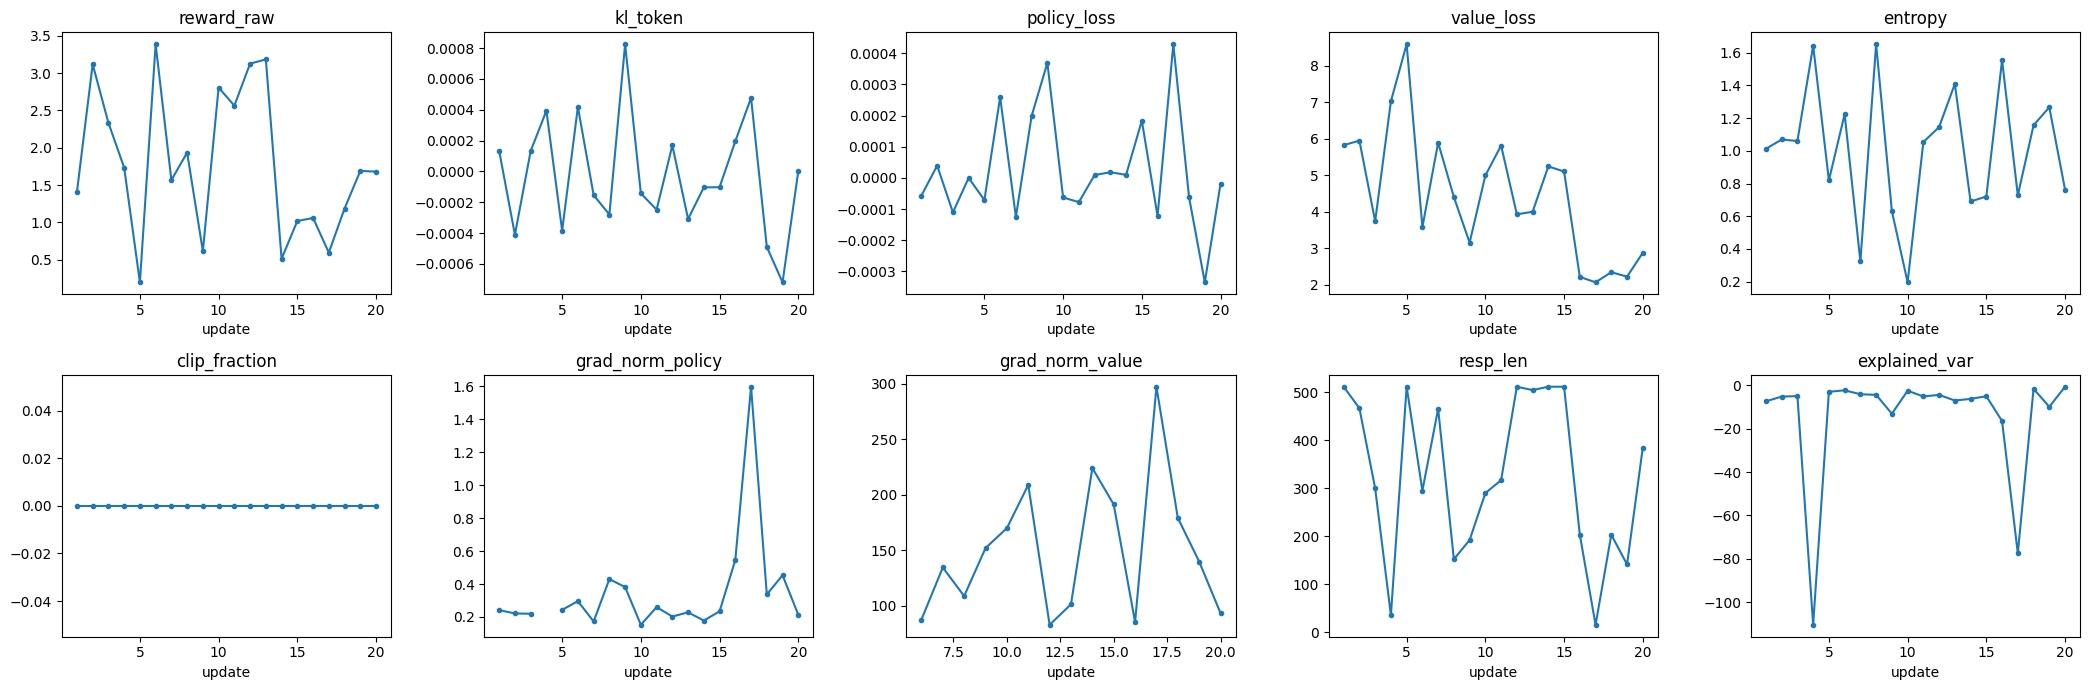

,update,reward_raw,kl_token,policy_loss,value_loss,entropy,clip_fraction,grad_norm_policy,grad_norm_value,resp_len,explained_var,clip_fraction_last_epoch,eos_rate,value_mean,return_mean,skipped_optimizer_steps
0,1,1.4072,0.0001,-0.0001,5.8236,1.0124,0,0.2416,NaN,512,-7.4207,0,0,-1.6310,-1.6179,2
1,2,3.1191,-0.0004,0.0000,5.9476,1.0694,0,0.2214,inf,467,-5.2381,0,1,-2.6098,-2.3549,2
2,3,2.3340,0.0001,-0.0001,3.7412,1.0600,0,0.2196,inf,300,-5.0246,0,1,-1.9168,-1.6034,2
3,4,1.7354,0.0004,0.0000,7.0242,1.6429,0,NaN,inf,35,-110.3623,0,1,1.6347,1.8137,3
4,5,0.1986,-0.0004,-0.0001,8.5849,0.8195,0,0.2434,inf,512,-3.0256,0,0,-0.8975,-0.9405,1
5,6,3.3867,0.0004,0.0003,3.5799,1.2240,0,0.2959,87.6050,295,-2.3487,0,1,-0.9673,-0.7059,0
6,7,1.5674,-0.0002,-0.0001,5.8916,0.3233,0,0.1726,134.5813,466,-4.1686,0,1,-2.8946,-2.7661,0
7,8,1.9355,-0.0003,0.0002,4.4043,1.6519,0,0.4299,108.8014,152,-4.4265,0,1,-0.8885,-0.5606,0
8,9,0.6152,0.0008,0.0004,3.1567,0.6318,0,0.3816,152.0042,192,-13.1411,0,1,-1.9125,-1.6924,0
9,10,2.8066,-0.0001,-0.0001,4.9937,0.1959,0,0.1523,169.9517,290,-2.5577,0,1,-2.1427,-1.8993,0


In [ ]:
import json, glob, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
R='results/task2_ppo'; os.makedirs(f'{R}/figures',exist_ok=True)
def log(name): return pd.read_json(f'{R}/train_log_{name}.jsonl', lines=True)
std=log('standard'); meta=json.load(open(f'{R}/run_meta_standard.json'))
print(f"Standard continuation: {meta['updates']} updates | wall-clock {meta['wall_clock_s']:.0f}s | peak VRAM {meta['peak_vram_gb']:.2f} GB | {meta['gpu']}")
cols=['reward_raw','kl_token','policy_loss','value_loss','entropy','clip_fraction','grad_norm_policy','grad_norm_value','resp_len','explained_var']
fig,ax=plt.subplots(2,5,figsize=(21,7))
for a,c in zip(ax.ravel(),cols):
    a.plot(std['update'],std[c],marker='o',ms=3); a.set_title(c); a.set_xlabel('update')
plt.tight_layout(); plt.savefig(f'{R}/figures/standard_trajectories.png',dpi=130); plt.show()
display(std[['update']+cols+['clip_fraction_last_epoch','eos_rate','value_mean','return_mean','skipped_optimizer_steps']].round(4))

== Clipping study: training stability ==


,reward_first3,reward_last3,reward_delta,kl_final,kl_max,gradnorm_max,gradnorm_cv,policy_loss_std,clip_frac_mean,ratio_max,value_loss_last,expl_var_mean,skipped_steps
eps0.05_kl0.1,2.2868,2.2965,0.0098,-0.0003,0.0004,0.4299,0.3192,0.0001,0.0,1.0295,4.4043,-17.7519,10.0
eps0.2_kl0.1,2.2868,2.2965,0.0098,-0.0003,0.0004,0.4299,0.3192,0.0001,0.0,1.0295,4.4043,-17.7519,10.0
eps0.5_kl0.1,2.2868,2.2965,0.0098,-0.0003,0.0004,0.4299,0.3192,0.0001,0.0,1.0295,4.4043,-17.7519,10.0


== KL-pressure study: training trajectories summary ==


,reward_first3,reward_last3,reward_delta,kl_final,kl_max,gradnorm_max,gradnorm_cv,policy_loss_std,clip_frac_mean,ratio_max,value_loss_last,expl_var_mean,skipped_steps
eps0.2_kl0,2.0446,1.5229,-0.5216,-0.0011,0.0006,1.9851,1.3281,0.0002,0.0,1.0305,3.2249,-21.5173,7.0
eps0.2_kl0.1,2.2868,2.2965,0.0098,-0.0003,0.0004,0.4299,0.3192,0.0001,0.0,1.0295,4.4043,-17.7519,10.0
eps0.2_kl0.2,2.1637,1.5786,-0.5851,-0.0003,0.0007,1.9931,1.3627,0.0001,0.0,1.0443,3.7207,-17.1946,7.0


== Held-out evaluation (same prompts/decoding/seed for all) ==


,n_prompts,reward_mean,reward_std,kl_token_mean,kl_seq,entropy_mean,len_mean,len_std,len_iqr,eos_rate,truncated_frac
name,,,,,,,,,,,
reference,64,1.7646,1.1505,0.0000,0.0000,0.8810,315.5312,274.4804,525.50,0.8594,0.1406
midpoint,64,1.6897,1.1657,0.0001,-0.0119,0.8927,319.4062,279.4094,556.75,0.8594,0.1406
standard,64,1.7481,1.1754,-0.0001,-0.0182,0.8910,312.6562,274.5515,525.50,0.8906,0.1094
eps0.05_kl0.1,64,1.8042,1.1294,-0.0000,-0.0192,0.8843,315.3750,269.2496,513.75,0.8750,0.1250
eps0.2_kl0,64,1.7795,1.1532,0.0000,-0.0271,0.8845,314.8281,273.6552,525.50,0.8906,0.1094
eps0.2_kl0.1,64,1.8042,1.1294,-0.0000,-0.0192,0.8843,315.3750,269.2496,513.75,0.8750,0.1250
eps0.2_kl0.2,64,1.7338,1.1584,0.0000,-0.0253,0.8834,309.6406,268.7815,481.50,0.8906,0.1094
eps0.5_kl0.1,64,1.8042,1.1294,-0.0000,-0.0192,0.8843,315.3750,269.2496,513.75,0.8750,0.1250


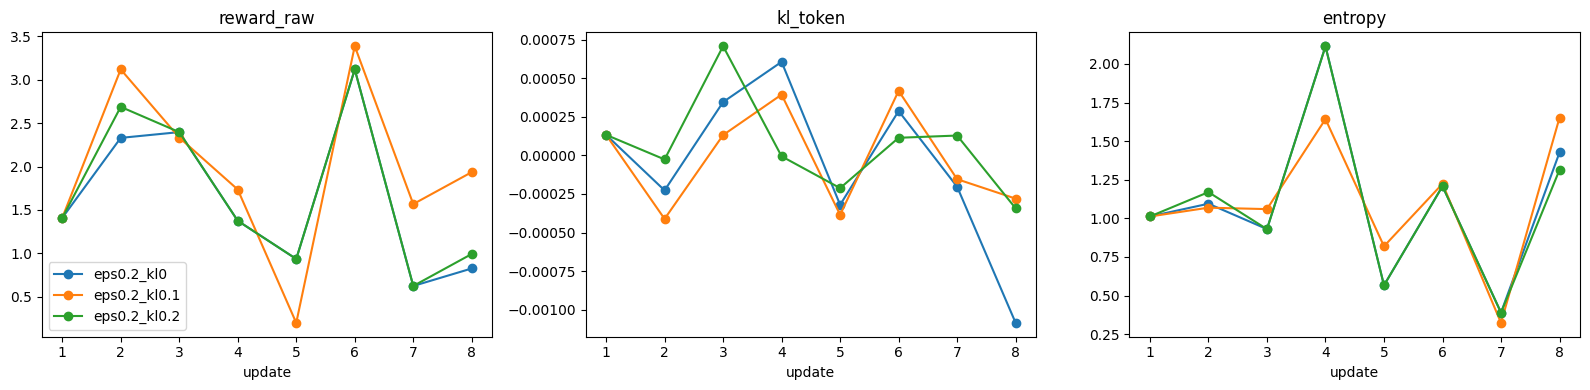

cache consistency: {'mean_abs_diff_policy_vs_cached_old': 0.5473389029502869, 'mean_abs_diff_reference_vs_cached_ref': 0.5471335053443909, 'n_rollouts': 32, 'n_tokens': 8814, 'reward_source': 'cache.effective_terminal_reward', 'reward_mean': 1.1042327880859375, 'source_indices': [124, 671, 510, 981, 175, 185, 953, 873, 796, 263, 507, 961, 280, 936, 254, 463, 436, 942, 184, 922, 755, 457, 832, 495, 803, 149, 569, 565, 236, 716, 805, 798]}
== Cached batch, loaded midpoint vs cached old log-probs ==


,eps,surrogate_clipped,surrogate_unclipped,clip_fraction,affected_fraction,ratio_mean_abs_dev,ratio_max,ratio_min,n_tokens
0,0.05,-0.08649,-0.01875,0.54799,0.26821,0.24677,29.86158,0.0,8814
1,0.20,-0.06477,-0.01875,0.33027,0.15827,0.24677,29.86158,0.0,8814
2,0.50,-0.04171,-0.01875,0.16848,0.07794,0.24677,29.86158,0.0,8814


== After probe gradient steps on the cached batch ==


,eps,lr_mult,clip_fraction,affected_fraction,ratio_mean_abs_dev,ratio_max,surrogate_clipped,surrogate_unclipped
0,0.05,1,0.54674,0.26764,0.24664,29.80268,-0.08639,-0.01865
1,0.20,1,0.32902,0.15827,0.24671,29.81255,-0.06467,-0.01864
2,0.50,1,0.16860,0.07817,0.24678,29.86166,-0.04165,-0.01865
3,0.05,20,0.54379,0.26957,0.24308,29.58104,-0.08265,-0.01519
4,0.20,20,0.32732,0.16043,0.24418,29.59990,-0.06067,-0.01475
5,0.50,20,0.16769,0.07908,0.24535,29.65193,-0.03722,-0.01432


In [ ]:
def stability(df):
    return {'reward_first3':df.reward_raw[:3].mean(),'reward_last3':df.reward_raw[-3:].mean(),
            'reward_delta':df.reward_raw[-3:].mean()-df.reward_raw[:3].mean(),
            'kl_final':df.kl_token.iloc[-1],'kl_max':df.kl_token.max(),
            'gradnorm_max':df.grad_norm_policy.max(),'gradnorm_cv':df.grad_norm_policy.std()/df.grad_norm_policy.mean(),
            'policy_loss_std':df.policy_loss.std(),'clip_frac_mean':df.clip_fraction.mean(),
            'ratio_max':df.ratio_max.max(),'value_loss_last':df.value_loss.iloc[-1],'expl_var_mean':df.explained_var.mean(),
            'skipped_steps':df.skipped_optimizer_steps.sum()}
clip_forks=['eps0.05_kl0.1','eps0.2_kl0.1','eps0.5_kl0.1']
kl_forks=['eps0.2_kl0','eps0.2_kl0.1','eps0.2_kl0.2']
print('== Clipping study: training stability =='); display(pd.DataFrame({n:stability(log(n)) for n in clip_forks}).T.round(4))
print('== KL-pressure study: training trajectories summary =='); display(pd.DataFrame({n:stability(log(n)) for n in kl_forks}).T.round(4))
ev=[json.load(open(f)) for f in glob.glob(f'{R}/eval_*.json')]
order=['reference','midpoint','standard']+sorted(set(clip_forks+kl_forks))
E=pd.DataFrame(ev).set_index('name').reindex([o for o in order if o in [e['name'] for e in ev]])
print('== Held-out evaluation (same prompts/decoding/seed for all) =='); display(E[['n_prompts','reward_mean','reward_std','kl_token_mean','kl_seq','entropy_mean','len_mean','len_std','len_iqr','eos_rate','truncated_frac']].round(4))
fig,ax=plt.subplots(1,3,figsize=(16,4))
for n in kl_forks:
    d=log(n)
    for a,c in zip(ax,['reward_raw','kl_token','entropy']): a.plot(d['update'],d[c],marker='o',label=n); a.set_title(c); a.set_xlabel('update')
ax[0].legend(); plt.tight_layout(); plt.savefig(f'{R}/figures/kl_study_trajectories.png',dpi=130); plt.show()
cs=json.load(open(f'{R}/cached_clipping_study.json'))
print('cache consistency:',cs['check'])
print('== Cached batch, loaded midpoint vs cached old log-probs =='); display(pd.DataFrame(cs['static']).round(5))
rows=[]
for p in cs['probes']:
    last=p['curve'][-1]; rows.append({'eps':p['eps'],'lr_mult':p['lr_mult'],**{k:last[k] for k in ['clip_fraction','affected_fraction','ratio_mean_abs_dev','ratio_max','surrogate_clipped','surrogate_unclipped']}})
print('== After probe gradient steps on the cached batch =='); display(pd.DataFrame(rows).round(5))

## Qualitative candidates (read these and choose your own examples)

In [ ]:
from common.metrics import safe_corr
def gens(n): return {r['source_index']:r for r in map(json.loads,open(f'{R}/generations_{n}.jsonl'))}
print('reward-vs-length correlation within each condition (reward-model length bias check):')
for n in E.index:
    g=list(gens(n).values()); print(f"  {n:16s} corr(reward,len)={safe_corr([x['reward'] for x in g],[x['length'] for x in g]):+.3f}  corr(reward,kl_seq)={safe_corr([x['reward'] for x in g],[x['kl_seq'] for x in g]):+.3f}")
def show(a,b,key,n=3,reverse=True):
    ga,gb=gens(a),gens(b); common=sorted(set(ga)&set(gb))
    ranked=sorted(common,key=lambda i:key(ga[i],gb[i]),reverse=reverse)[:n]
    for i in ranked:
        print('='*100); print('PROMPT [%d]:'%i, ga[i]['prompt'][-1]['content'][:300].replace('\n',' '))
        for tag,g in ((a,ga[i]),(b,gb[i])):
            print(f"--- {tag}: reward={g['reward']:.2f} len={g['length']} kl_seq={g['kl_seq']:.1f} eos={g['terminated']}"); print(g['response'][:600].replace('\n',' '))
print('\n##### DISAGREE: beta_KL=0 gets higher reward than beta_KL=0.2 but a longer / unterminated response #####')
show('eps0.2_kl0','eps0.2_kl0.2',lambda x,y:(x['reward']-y['reward'])+0.002*(x['length']-y['length'])-(2 if x['terminated'] else 0))
print('\n##### AGREE: beta_KL=0 higher reward AND not longer #####')
show('eps0.2_kl0','eps0.2_kl0.2',lambda x,y:(x['reward']-y['reward'])-0.01*max(0,x['length']-y['length']))

reward-vs-length correlation within each condition (reward-model length bias check):
  reference        corr(reward,len)=+0.459  corr(reward,kl_seq)=+nan
  midpoint         corr(reward,len)=+0.368  corr(reward,kl_seq)=+0.029
  standard         corr(reward,len)=+0.494  corr(reward,kl_seq)=-0.070
  eps0.05_kl0.1    corr(reward,len)=+0.443  corr(reward,kl_seq)=-0.087
  eps0.2_kl0       corr(reward,len)=+0.524  corr(reward,kl_seq)=-0.127
  eps0.2_kl0.1     corr(reward,len)=+0.443  corr(reward,kl_seq)=-0.087
  eps0.2_kl0.2     corr(reward,len)=+0.472  corr(reward,kl_seq)=-0.144
  eps0.5_kl0.1     corr(reward,len)=+0.443  corr(reward,kl_seq)=-0.087

##### DISAGREE: beta_KL=0 gets higher reward than beta_KL=0.2 but a longer / unterminated response #####
PROMPT [40]: Please provide a comprehensive guide on the step-by-step process of utilizing Apache Pulsar for seamless communication and event-driven architectures in a distributed system, including installation, configuration, and deployment p

## Backup + download

In [ ]:
# Timestamped backup of results + run metadata + code snapshot to Drive. Safe to re-run after any step.
import shutil, time, os, glob, subprocess
D='/content/drive/MyDrive/ATML_PA2_task2'
dst=f"{D}/backup_{time.strftime('%Y%m%d_%H%M%S')}"
os.makedirs(dst,exist_ok=True)
if os.path.isdir('results/task2_ppo'):
    shutil.copytree(os.path.realpath('results/task2_ppo'), f'{dst}/results_task2_ppo', dirs_exist_ok=True)
for f in glob.glob('outputs/task2_ppo/*/run_meta.json'):
    name=f.split('/')[-2]; os.makedirs(f'{dst}/run_meta',exist_ok=True); shutil.copy(f,f'{dst}/run_meta/{name}.json')
for d in ('task2_ppo','tests','common'):
    shutil.copytree(d, f'{dst}/code/{d}', dirs_exist_ok=True, ignore=shutil.ignore_patterns('__pycache__'))
os.makedirs(f'{dst}/code/configs',exist_ok=True)
for f in glob.glob('configs/*.yaml'): shutil.copy(f,f'{dst}/code/configs/')
print('Backed up to', dst)

Backed up to /content/drive/MyDrive/ATML_PA2_task2/backup_20261012_203033


In [ ]:
!zip -qr task2_results.zip results/task2_ppo outputs/task2_ppo/*/run_meta.json
from google.colab import files
files.download('task2_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>